## Represent the 2-qubit Bell state




### Step 1: Map the problem to circuits and operators

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc


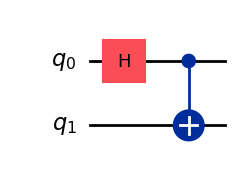

In [ ]:
import qiskit
from qiskit import QuantumCircuit

qiskit.__version__

"""
Bell state: it means the two qubits are completely entangled. They're not independent anymore.
If a 0 is obtained for the q1, then q2 is also 0, and viceversa.
First, the H gate is applied on the first qubit (to stablish a superposition state. 50% chance of 0 and 1).
Then, the CNOT (controlled not) correlates both qubits. This ends up in... two possible results with the same probability. 00) or 11)
"""

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

qc.draw(output='mpl')

#qc.measure_all()



In [ ]:
from qiskit.quantum_info import Pauli

"""
Observables are a physical property that can be measured in a system.
And Pauli matrices (I, X, Y, Z) are key operators that represent this measures.

- I(identity): leaves the qubit unchanged (no measure, nor transformation on it)
- X(Bit-flip/Pauli-X): Equivalent to the classic NOT. Measures in the diagonal base, +) and -)
- Z(Phase-flip/Pauli-Z): Measures on the standard computational base, 0) and 1)

ZZ: Measures the Z operator on qubit 0, and the Z operator on qubit 1, simultaneously. Used to evaluate the standard base correlation between qubits.
ZI: Measures Z in the qubit 0, and I in the qubit 1. This means we only measure qubit0.
XX: Measures the X operator in both qubits simultaneously, to evaluate correlations in the diagonal base.
"""

ZZ = Pauli('ZZ')
ZI = Pauli('ZI')
IZ = Pauli('IZ')
XX = Pauli('XX')
XI = Pauli('XI')
IX = Pauli('IX')

observables = [ZZ, ZI, IZ, XX, XI, IX]



### Step 2: Optimize the observables

### Step 3: Execute on the backend

In [ ]:
from qiskit_aer.primitives import Estimator

estimator = Estimator()

job = estimator.run([qc] * len(observables), observables) # we multiply the nº of qubits by the nº of observables. it is what the Estimator asks for.

job.result() # ZZ ZI IZ XX XI IX  -->  1, 0, 0, 1, 0, 0

EstimatorResult(values=array([ 1.        , -0.04492188, -0.04492188,  1.        , -0.06054688,
       -0.06054688]), metadata=[{'shots': 1024, 'variance': 0.0, 'simulator_metadata': [{'time_taken': 0.00100085, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 0, 'input_qubit_map': [[1, 1], [0, 0]], 'method': 'stabilizer', 'device': 'CPU', 'num_qubits': 2, 'sample_measure_time': 0.00038854, 'active_input_qubits': [0, 1], 'num_clbits': 2, 'remapped_qubits': False, 'runtime_parameter_bind': False, 'max_memory_mb': 12975, 'noise': 'ideal', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusion': {'enabled': False}}]}, {'shots': 1024, 'variance': 0.9979820251464844, 'simulator_metadata': [{'time_taken': 0.00100085, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 0, 'input_qubit_map': [[1, 1], [0, 0]], 'method': 'stabilizer', 'device': 'CPU', 'num_qubits': 2, 'sample_measure_time': 0.00038

### Step 4: Post-process (and plotting)

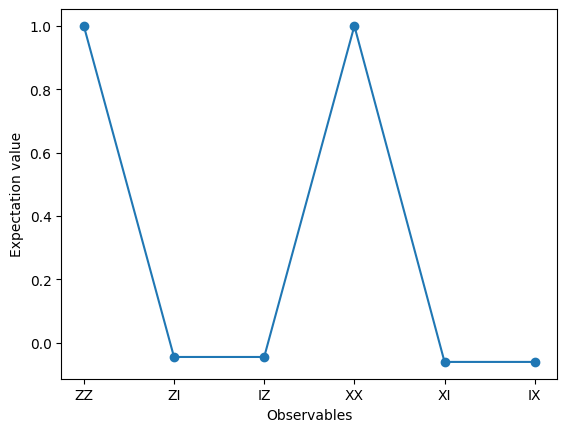

In [ ]:
import matplotlib.pyplot as plt

data = ['ZZ', 'ZI', 'IZ', 'XX', 'XI', 'IX']
#counts = job.result().get_counts()
values = job.result().values

plt.plot(data, values, '-o')
plt.xlabel('Observables')
plt.ylabel('Expectation value')
plt.show()


# Extend the example to an $n$-qubit GHZ state

It is a similar state compared to the two qubit Bell state. 00 and 11 superposition

0000 and 1111, or as n qubits in the system. It's almost the same.

### Step 1: Map the problem to circuits and operators

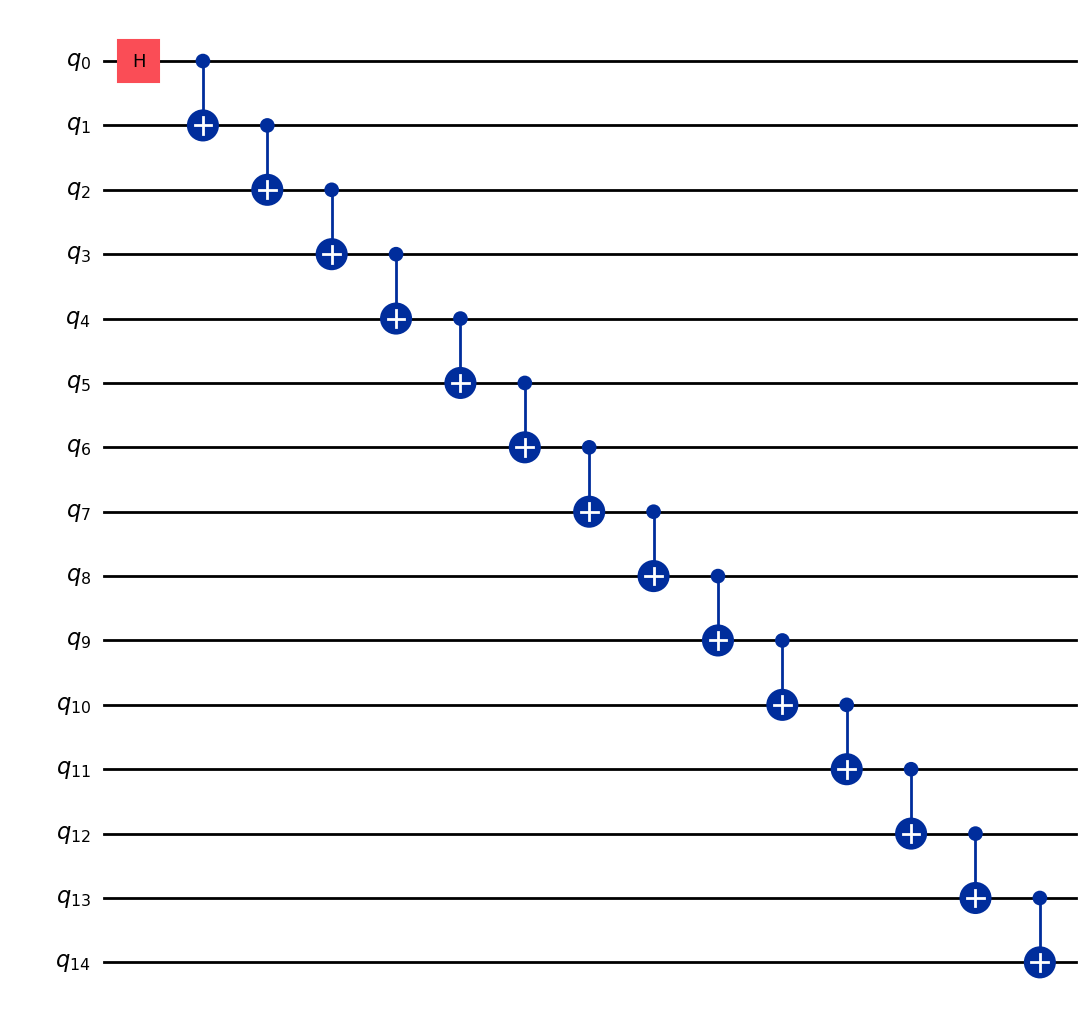

In [ ]:
def get_qc_for_n_qubit_GHZ_state(n):
  qc = QuantumCircuit(n)  # quantum circuit with n register
  qc.h(0) #hadamard

  for i in range(n-1):
    qc.cx(i, i+1)
  return qc

n = 15 #100 #10
qc = get_qc_for_n_qubit_GHZ_state(n)
qc.draw(output='mpl')


In [ ]:
from qiskit.quantum_info import SparsePauliOp

operator_strings = ['Z' + 'I'*i + 'Z' + 'I' * (n-2-i) for i in range(n-1)]
print(operator_strings)
print(len(operator_strings)) #we expect n-1

operators = [SparsePauliOp(operator_string) for operator_string in operator_strings]
#print(operators)


['ZZIIIIIIIIIIIII', 'ZIZIIIIIIIIIIII', 'ZIIZIIIIIIIIIII', 'ZIIIZIIIIIIIIII', 'ZIIIIZIIIIIIIII', 'ZIIIIIZIIIIIIII', 'ZIIIIIIZIIIIIII', 'ZIIIIIIIZIIIIII', 'ZIIIIIIIIZIIIII', 'ZIIIIIIIIIZIIII', 'ZIIIIIIIIIIZIII', 'ZIIIIIIIIIIIZII', 'ZIIIIIIIIIIIIZI', 'ZIIIIIIIIIIIIIZ']
14


### Step 2: Optimize the problem for quantum execution

We could here... transpile the circuit for the backend, such that it matches the local conectivity, native gate requirements... merge two qubits gates...
we can use symmetries of the problem, or properties to optimize the execution. For this specific case, we'll use instead a simulated chip.

In [ ]:
!pip install -q qiskit-ibm-runtime

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Upload a simulated IBM chip of 127 qubits (local)
backend = FakeBrisbane()

# We create an optimization manager (pass manager) with opt. level = 1
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)

In [ ]:
# We transpile our ideal quantum circuit, to the adapted (simulated) hardware.
qc_transpiled = pass_manager.run(qc)

# Adjust the Pauli operators to the new physical map of qubits
operators_transpiled_list = [op.apply_layout(qc_transpiled.layout) for op in operators]

### Step 3: Execute on the backend

Basic properties about it. Transpilation, noise...

In [ ]:
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Estimator

# 1. Create a simple noise model
noise_model = NoiseModel()

# We add a 1% despolarization error to the 1qubit operators (H), for example.
error_1q = depolarizing_error(0.01, 1)
noise_model.add_all_qubit_quantum_error(error_1q, ['h'])

# We add a 3% despolarization error to the 2qubits operators (CNOT)
error_2q = depolarizing_error(0.03, 2)
noise_model.add_all_qubit_quantum_error(error_2q, ['cx'])

# 2. Initialize the standard Estimator, passing the noise_model
estimator = Estimator(backend_options={"noise_model": noise_model})
# In fact, the nº of states grows exponentially, with the nº of qubits... so for a simulation with FakeBarbone, 15qubits is still possible.

In [ ]:
"""
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import EstimatorOptions

options = EstimatorOptions()
options.resilience_level = 1
options.optimization_level = 0
options.dynamical_decoupling.enable = True
options.dynamical_decoupling.sequence_type = "XY4"

estimator = Estimator(backend, options=options)

job =  estimator.run(((qc_transpiled, operators_transpiled_list)))
job_id = job.job_id()
print(job_id)
"""

# Execute the transpiled circuit with the operator list
# The format for the standard estimator is: (circuit, observables)
job = estimator.run(
        [qc_transpiled] * len(operators_transpiled_list),
        operators_transpiled_list
      )

# We directly obtain the results
result = job.result()
values = result.values


### Step 4: Post-process and plot

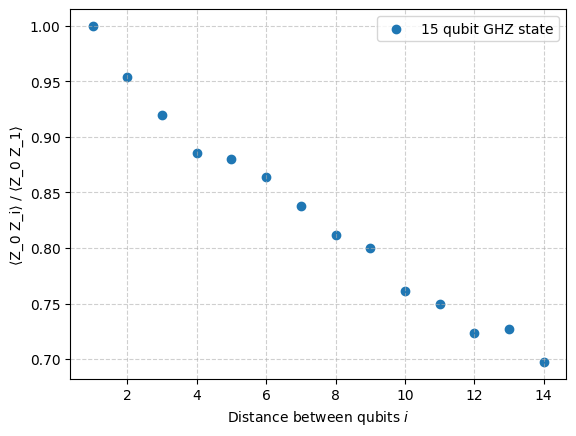

In [ ]:
import matplotlib.pyplot as plt

# We normalize the values
values = [v / values[0] if values[0] != 0 else v for v in values]
# Create the X axis adjusted to the nº of evaluated operators
data = list(range(1, len(values) + 1))

plt.scatter(data, values, marker='o', label='15 qubit GHZ state')
plt.xlabel('Distance between qubits $i$')
plt.ylabel(r'⟨Z_0 Z_i⟩ / ⟨Z_0 Z_1⟩')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()